# Misión Asíncrona: Cazando al Falso Influencer
Han sido contratados como analistas de fraude por una agencia de marketing deportivo. Tienen sobre la mesa dos perfiles para patrocinar: AMATEUR_1 y GARNACHO.

Le han pedido al equipo de Backend un reporte de quién sigue a quién, y les han entregado el archivo export_api_influencers.csv.

Como suele pasar en la industria, el archivo no es un grafo, es un volcado de base de datos. Contiene los metadatos del usuario y una columna de texto llamada Cuentas_Que_Sigue donde vienen empalmados todos los nombres de las personas a las que sigue ese usuario, separados por comas.

Su misión es extraer la red, construir el grafo y descubrir matemáticamente quién es el fraude.

In [6]:
import pandas as pd
df = pd.read_csv("./export_api_influencers.csv")
print(df.head(10))

  Usuario Ubicacion Fecha_Creacion Cuentas_Que_Sigue
0   Bot_5     India     2023-05-06         AMATEUR_1
1   fan_6    Mexico     2023-07-14   GARNACHO, MESSI
2  Bot_11     India     2023-02-14         AMATEUR_1
3   Bot_1     India     2023-11-24         AMATEUR_1
4  Bot_36     India     2023-06-24         AMATEUR_1
5   Fan_4    Mexico     2023-05-29          GARNACHO
6  Bot_29     India     2023-08-18         AMATEUR_1
7  Bot_13     India     2023-08-05         AMATEUR_1
8  Bot_18     India     2023-04-30         AMATEUR_1
9   Fan_7    Mexico     2023-11-22          GARNACHO


## Fase 1: Data Engineering (La Explosión) 
Para poder usar networkx, primero necesitan una Lista de Aristas purificada. Abran un nuevo Jupyter Notebook, importen pandas y realicen la siguiente tubería de datos (Data Pipeline):

1. Limpieza Estructural: Eliminen las filas donde la columna Cuentas_Que_Sigue esté vacía (nula). Estandaricen la columna Usuario a MAYÚSCULAS y quítenle los espacios al inicio/final. Eliminen usuarios duplicados.
2. La Explosión: Separen los nombres de la columna Cuentas_Que_Sigue usando .str.split(','). Luego, utilicen la función mágica de Pandas .explode() sobre esa columna para aplanar la tabla y convertirla en una verdadera lista de Origen -> Destino.
3. Purificación Post-Explosión: Vuelvan a limpiar los textos de la columna destino (mayúsculas y sin espacios extra). Finalmente, eliminen los Self-Loops (Registros donde el Usuario aparezca siguiéndose a sí mismo).

In [7]:
# --- 1. Limpieza estructural ---
df_cleaned = df.dropna(subset=["Cuentas_Que_Sigue"]).copy()
df_cleaned["Usuario"] = df_cleaned["Usuario"].str.strip().str.upper()
df_cleaned = df_cleaned.drop_duplicates(subset=["Usuario"])
print("Filas originales:", len(df), "| limpias:", len(df_cleaned))

# --- 2. La explosión ---
df_cleaned["Cuentas_Que_Sigue"] = df_cleaned["Cuentas_Que_Sigue"].str.split(",")
aristas = df_cleaned.explode("Cuentas_Que_Sigue")

# --- 3. Purificación post-explosión ---
aristas["Cuentas_Que_Sigue"] = aristas["Cuentas_Que_Sigue"].str.strip().str.upper()
aristas = aristas[aristas["Usuario"] != aristas["Cuentas_Que_Sigue"]]  # sin self-loops
aristas = aristas.rename(columns={"Usuario": "Origen", "Cuentas_Que_Sigue": "Destino"})[["Origen", "Destino"]]

display(aristas)

Filas originales: 75 | limpias: 65


,Origen,Destino
0,BOT_5,AMATEUR_1
1,FAN_6,GARNACHO
1,FAN_6,MESSI
2,BOT_11,AMATEUR_1
3,BOT_1,AMATEUR_1
...,...,...
67,BOT_22,AMATEUR_1
68,BOT_3,AMATEUR_1
69,BOT_24,AMATEUR_1
71,FAN_3,GARNACHO


## Fase 2: El Engaño de la Popularidad Con su Lista de Aristas terminada:

1. Importen networkx y conviertan su tabla en un Grafo Dirigido (nx.DiGraph).
2. Calculen la Centralidad de Entrada (nx.in_degree_centrality).
3. Impriman a los 3 usuarios con el puntaje más alto.
    - Pregunta: A simple vista, ¿quién parece ser el rey de la red? AMATEUR_1


In [8]:
import networkx as nx
import matplotlib.pyplot as plt

DG = nx.from_pandas_edgelist(aristas, source="Origen", target="Destino", create_using=nx.DiGraph())
print(f"Nodos: {DG.number_of_nodes()}  |  Aristas: {DG.number_of_edges()}")

in_centralidad = nx.in_degree_centrality(DG)
print("\nTop 3 In-Degree Centrality:")
for user, c in sorted(in_centralidad.items(), key=lambda x: -x[1])[:3]:
    print(f"  {user:<12} {c:.4f}")

Nodos: 66  |  Aristas: 97

Top 3 In-Degree Centrality:
  AMATEUR_1    0.7231
  GARNACHO     0.2000
  MESSI        0.1538


## Fase 3: La Verdad Topológica (Las Métricas) 
Es hora de usar los algoritmos que vimos en los videos de hoy para auditar la red.

1. Calculen el PageRank (nx.pagerank). ¿Quién tiene ahora la verdadera autoridad?
2. Conviertan el grafo a No Dirigido y calculen el Coeficiente de Clustering (nx.clustering). Impriman el valor exacto de AMATEUR_1 y el de GARNACHO.

Top 5 PageRank:
  AMATEUR_1    0.1969
  DE_PAUL      0.0883
  GARNACHO     0.0843
  SUAREZ       0.0794
  OTAMENDI     0.0686

Clustering AMATEUR_1: 0
Clustering GARNACHO:  0.13333333333333333
AMATEUR_1  seguidores: 47 | PageRank promedio de seguidores: 0.0048
GARNACHO   seguidores: 13 | PageRank promedio de seguidores: 0.0184


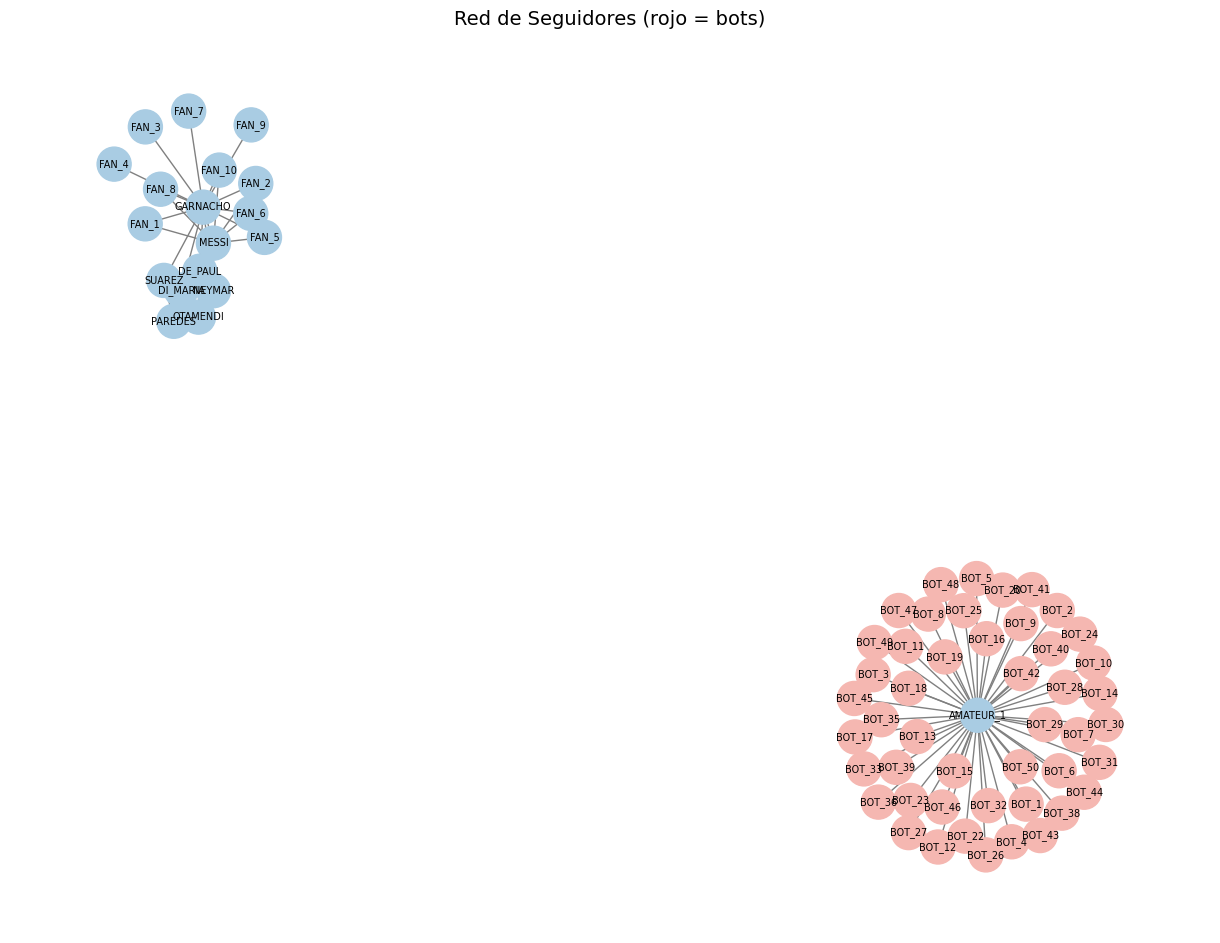

In [9]:
# 1. PageRank
pagerank = nx.pagerank(DG)
print("Top 5 PageRank:")
for user, pr in sorted(pagerank.items(), key=lambda x: -x[1])[:5]:
    print(f"  {user:<12} {pr:.4f}")

# 2. Clustering sobre el grafo no dirigido
G_und = DG.to_undirected()
clustering = nx.clustering(G_und)
print("\nClustering AMATEUR_1:", clustering["AMATEUR_1"])
print("Clustering GARNACHO: ", clustering["GARNACHO"])

# ¿Quién lo sigue? PageRank promedio de sus seguidores
for user in ["AMATEUR_1", "GARNACHO"]:
    seguidores = list(DG.predecessors(user))
    pr_prom = sum(pagerank[s] for s in seguidores) / len(seguidores)
    print(f"{user:<10} seguidores: {len(seguidores):>2} | PageRank promedio de seguidores: {pr_prom:.4f}")

plt.figure(figsize=(12, 9))
pos = nx.spring_layout(G_und, seed=42)
colores = ["#F5B7B1" if n.startswith("BOT") else "#A9CCE3" for n in G_und.nodes()]
nx.draw(G_und, pos, with_labels=True, node_color=colores, node_size=600, font_size=7, edge_color="gray")
plt.title("Red de Seguidores (rojo = bots)", fontsize=14)
plt.show()

## Veredicto Final (Markdown): 
Cierren su notebook con una celda de texto. Usando estrictamente sus resultados matemáticos de PageRank y Clustering, argumenten de forma técnica y profesional:

**¿Quién compró bots y por qué?** AMATEUR_1. 
Tiene clustering 0: ninguno de sus 47 seguidores se sigue entre sí, es una estrella perfecta.  
Su PageRank alto (0.197) es solo por volumen, sus seguidores tienen el PageRank mínimo de la red (promedio 0.0048). Son cuentas sin autoridad, todas de India y que solo lo siguen a él, típico de una granja de bots.  

**¿Quién es el influencer real y por qué?** GARNACHO. 
Tiene clustering 0.13, sus seguidores se siguen entre ellos y forman una comunidad orgánica.  
Lo siguen nodos importantes (MESSI, NEYMAR, SUAREZ) con PageRank promedio de 0.0184, casi 4 veces más que los de AMATEUR_1. Con solo 13 seguidores queda en el top 3 de PageRank, porque importa quién te sigue y no cuántos.
